# 서울시 고령 거주인구 EDA

`seoul_eda.ipynb`의 2번(60대 이상 유동인구 지도)과 3번(사각지대 지도)을 60세 이상 **거주인구**로 다시 그린다.
유동인구는 안심구역 안에서만 볼 수 있지만, 거주인구는 공개 자료라 로컬에서 바로 실행된다.
지금 유동인구 그림은 모의 자료라서, 실제 값으로 수요 분포를 확인할 수 있는 것은 이 노트북뿐이다.

## 자료

| 자료 | 출처 | 쓰임 |
|---|---|---|
| 지역별(행정동) 성별 연령별 주민등록 인구수, 2026.9.30 | 공공데이터포털, 행정안전부 | 행정동별 60세 이상 인구 |
| 행정동 경계 ver20260701 | github.com/vuski/admdongkor (SGIS 행정동 경계 보정본) | 격자에 행정동 붙이기 |
| `Seoul_Test_Population.csv` | 출처 확인 필요. 100m 격자 총인구 | 행정동 인구를 격자에 나누는 비율 |
| `SeoulBoundary.shp` | SGIS 통계지리정보서비스 | 자치구 경계 |
| `SeoulCoolingCenter.csv` | 서울 열린데이터광장 OA-21065 | 기존 쉼터 위치 |

## 방법

주민등록인구는 행정동 단위까지만 나오고, 격자 인구에는 연령이 없다. 그래서 행정동의 60세 이상 인구를 그 동 안 격자들에 격자 총인구 비율대로 나눠 담는다.

> 격자의 60세 이상 인구 = 행정동 60세 이상 인구 × (격자 총인구 ÷ 그 행정동 격자 총인구 합)

행정동 합계는 주민등록 통계와 정확히 같다. 대신 **같은 행정동 안에서는 고령 비율이 같다**고 가정한다. 한 동 안에서 노인이 특정 단지에 몰려 사는 차이는 드러나지 않는다.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from shapely.geometry import box

# 한글 글꼴. 설치된 것 중 먼저 찾은 것을 쓴다.
installed = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
    if font_name in installed:
        plt.rcParams["font.family"] = font_name
        break
else:
    print("한글 글꼴을 찾지 못했다. 그림의 한글이 깨지면 font_name 목록에 설치된 글꼴 이름을 추가한다.")
plt.rcParams["axes.unicode_minus"] = False

# 색. seoul_eda.ipynb와 같다.
INK, INK_SUB, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#2a78d6", "#104281"]
ORANGE_RAMP = ["#f6bfa6", "#eb6834", "#a83c12"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BORDER, "axes.labelcolor": INK_SUB, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_SUB, "axes.titlelocation": "left",
})

## 0. 설정

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "2_데이터").exists())
RAW = ROOT / "2_데이터" / "원본"
INPUT = ROOT / "2_데이터" / "모형입력"
OUT = ROOT / "4_결과" / "서울_EDA_거주인구"

POP_PATH = RAW / "행정안전부_지역별(행정동) 성별 연령별 주민등록 인구수_20260930.csv"
DONG_PATH = RAW / "HangJeongDong_ver20260701.geojson"
GRID_PATH = INPUT / "Seoul_Test_Population.csv"
GU_PATH = INPUT / "SeoulBoundary.shp"
SHELTER_PATH = INPUT / "SeoulCoolingCenter.csv"

AGE_MIN = 60                  # 유동인구 그림의 60대 이상과 맞춘다. 65로 바꾸면 법정 노인 기준
COVERAGE_DISTANCE_M = 219     # Seoul.ipynb, seoul_eda.ipynb와 같은 값
BLOCK_M = 500                 # 지도에서 격자를 묶는 구획 크기 (m)
TOP_N = 10                    # 지도에 순위를 붙일 구획 수
STALE_RATIO = 0.5             # 격자 총인구가 주민등록인구의 이 비율 미만인 동은 균등배분

SAVE = True
OUT.mkdir(parents=True, exist_ok=True)

missing = [str(f) for f in (POP_PATH, DONG_PATH, GRID_PATH, GU_PATH, SHELTER_PATH) if not f.exists()]
if missing:
    raise FileNotFoundError("다음 파일을 찾을 수 없다: " + ", ".join(missing))
print("입력 파일 5개 확인")

입력 파일 5개 확인


## 0-1. 그림 함수

`seoul_eda.ipynb`의 지도 함수와 같다.

In [3]:
def save(fig, name):
    if SAVE:
        fig.savefig(OUT / name, dpi=200, bbox_inches="tight")


def base_map(ax):
    gu.plot(ax=ax, facecolor=LAND, edgecolor=BORDER, linewidth=0.6, zorder=1)
    ax.set_aspect("equal")
    ax.set_axis_off()


def rank_badges(ax, blocks):
    """구획 중심에 순위 번호를 붙인다. blocks는 순위대로 정렬된 GeoDataFrame."""
    blocks.boundary.plot(ax=ax, color=INK, linewidth=1.1, zorder=7)
    pts = blocks.representative_point()
    xy = np.column_stack([pts.x, pts.y]).astype(float)
    min_gap = BLOCK_M * 1.9   # 번호 원 지름보다 조금 크게
    for _ in range(30):       # 붙어 있는 구획의 번호는 서로 밀어낸다
        for i in range(len(xy)):
            for j in range(i + 1, len(xy)):
                d = xy[j] - xy[i]
                dist = np.hypot(*d)
                if dist < min_gap:
                    push = (d / dist if dist > 0 else np.array([1.0, 0.0])) * (min_gap - dist) / 2
                    xy[i] -= push
                    xy[j] += push
    for rank, (x, y) in enumerate(xy, start=1):
        ax.text(x, y, str(rank), fontsize=8, fontweight="bold", color=INK, ha="center",
                va="center", zorder=8,
                bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor=INK, linewidth=0.9))


def gu_labels(ax, halo=LAND):
    for name, pt in zip(gu["gu"], gu.representative_point()):
        ax.text(pt.x, pt.y, name, fontsize=7.5, color=INK_SUB, ha="center", va="center", zorder=6,
                path_effects=[pe.withStroke(linewidth=2.2, foreground=halo)])


def rank_legend(ax, colors, labels, title):
    handles = [Patch(color=c, label=l) for c, l in zip(colors, labels)]
    handles.append(Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor="white",
                          markeredgecolor=INK, label=f"상위 {TOP_N}곳 (번호는 순위)"))
    ax.legend(handles=handles, title=title, frameon=False, loc="lower left", fontsize=9,
              title_fontsize=9, labelcolor=INK_SUB)

## 1. 행정동별 60세 이상 인구

연령 열은 `0세남자`부터 `110세이상 남자`까지 한 살 단위다. 열 이름의 숫자가 `AGE_MIN` 이상인 열을 남녀 모두 더한다.

In [4]:
pop = pd.read_csv(POP_PATH, encoding="cp949", dtype={"행정기관코드": str})
pop = pop[pop["시도명"] == "서울특별시"].copy()


def age_of(col):
    m = re.match(r"(\d+)세(이상 )?(남자|여자)$", col)
    return int(m.group(1)) if m else None


age_cols = [c for c in pop.columns if age_of(c) is not None]
old_cols = [c for c in age_cols if age_of(c) >= AGE_MIN]
assert len(age_cols) == 222, f"연령 열이 {len(age_cols)}개다. 파일 형식이 바뀌었는지 확인한다."
assert (pop[age_cols].sum(axis=1) == pop["계"]).all(), "연령 열 합계가 '계'와 다르다."

pop["pop_old"] = pop[old_cols].sum(axis=1)
dong_pop = pop.set_index("행정기관코드")[["시군구명", "읍면동명", "계", "pop_old"]]

print("기준일:", pop["기준연월"].iat[0])
print("서울 행정동:", f"{len(dong_pop):,}개")
print(f"서울 주민등록인구 {dong_pop['계'].sum():,}명 중 {AGE_MIN}세 이상 {dong_pop['pop_old'].sum():,}명"
      f" ({dong_pop['pop_old'].sum() / dong_pop['계'].sum() * 100:.1f}%)")

기준일: 2026-09-30
서울 행정동: 427개
서울 주민등록인구 9,279,861명 중 60세 이상 2,613,628명 (28.2%)


## 2. 격자에 나눠 담기

100m 격자 중심점에 행정동을 붙이고, 행정동의 60세 이상 인구를 격자 총인구 비율대로 나눈다.
총인구가 0인 격자에는 아무것도 담지 않는다.

격자 총인구와 주민등록인구는 기준 시점이 달라서 동마다 어긋난다. 격자 시점 이후 재건축 단지가 들어선 동은 격자 인구가 주민등록인구보다 훨씬 적다.
둔촌1동은 격자 88칸 중 5칸에만 인구가 있어서, 그대로 나누면 동 전체의 고령 인구가 5칸에 몰려 서울 1위 구획이 된다.
그래서 격자 총인구가 주민등록인구의 `STALE_RATIO` 미만인 동은 격자 인구를 버리고, 동 안의 모든 격자에 고르게 나눈다. 해당 동은 아래 표에 `균등배분`으로 표시된다.

In [5]:
gu = gpd.read_file(GU_PATH).to_crs(5179).rename(columns={"SIGUNGU_NM": "gu"})[["gu", "geometry"]]
dong = gpd.read_file(DONG_PATH)
dong = dong[dong["sidonm"] == "서울특별시"].to_crs(5179)[["adm_cd2", "sggnm", "geometry"]]

code_gap = set(dong_pop.index) ^ set(dong["adm_cd2"])
assert not code_gap, f"인구와 경계의 행정동 코드가 맞지 않는다: {sorted(code_gap)}"

# 인구 0인 격자도 읽는다. 균등배분하는 동에서 쓴다.
grid = pd.read_csv(GRID_PATH, usecols=["GRID_CD", "population", "경도", "위도"])
grid = gpd.GeoDataFrame(grid, geometry=gpd.points_from_xy(grid["경도"], grid["위도"]), crs=4326).to_crs(5179)
x0, y0, x1, y1 = dong.total_bounds
grid = grid.cx[x0:x1, y0:y1]
grid = gpd.sjoin(grid, dong, how="inner", predicate="within").drop(columns="index_right")
grid = grid.rename(columns={"sggnm": "gu"}).reset_index(drop=True)

grid_sum = grid.groupby("adm_cd2")["population"].sum()
ratio = (grid_sum / dong_pop["계"]).rename("격자/주민등록")
stale = ratio.index[ratio < STALE_RATIO]

# 나누는 비율. 보통은 격자 총인구, 균등배분 동은 격자마다 1.
grid["weight"] = grid["population"].astype(float)
grid.loc[grid["adm_cd2"].isin(stale), "weight"] = 1.0
grid = grid[grid["weight"] > 0].reset_index(drop=True)

w_sum = grid.groupby("adm_cd2")["weight"].sum()
no_grid = dong_pop.index.difference(w_sum.index)
assert no_grid.empty, f"격자가 없는 행정동: {list(no_grid)}"

grid["pop_old"] = grid["adm_cd2"].map(dong_pop["pop_old"]) * grid["weight"] / grid["adm_cd2"].map(w_sum)
assert np.isclose(grid["pop_old"].sum(), dong_pop["pop_old"].sum())

print("고령 인구를 담은 격자:", f"{len(grid):,}개")
print(f"격자 총인구 {grid_sum.sum():,.0f}명, 주민등록인구 {dong_pop['계'].sum():,}명")
print(f"균등배분한 동: {len(stale)}개")

odd = dong_pop.join(ratio)
odd = odd[(odd["격자/주민등록"] < STALE_RATIO) | (odd["격자/주민등록"] > 2)].copy()
odd["처리"] = np.where(odd.index.isin(stale), "균등배분", "격자 비율")
display(odd[["시군구명", "읍면동명", "계", "pop_old", "격자/주민등록", "처리"]]
        .rename(columns={"계": "주민등록인구", "pop_old": f"{AGE_MIN}세이상"})
        .sort_values("격자/주민등록")
        .style.format({"주민등록인구": "{:,}", f"{AGE_MIN}세이상": "{:,}", "격자/주민등록": "{:.2f}"}))

고령 인구를 담은 격자: 31,165개
격자 총인구 9,388,649명, 주민등록인구 9,279,861명
균등배분한 동: 3개


,시군구명,읍면동명,주민등록인구,60세이상,격자/주민등록,처리
행정기관코드,,,,,,
1174069000,강동구,둔촌제1동,"33,099","7,200",0.01,균등배분
1165055000,서초구,반포본동,"4,230",868,0.03,균등배분
1168066000,강남구,개포1동,"26,457","6,404",0.24,균등배분
1117070000,용산구,보광동,"4,960","1,760",2.65,격자 비율


## 3. 60세 이상 거주인구 지도

`seoul_eda.ipynb` 2번 그림과 같은 형식이다. 100m 격자를 500m 구획으로 묶어 5분위로 칠하고, 상위 10곳에 번호를 붙인다.

500m 구획: 2,024개


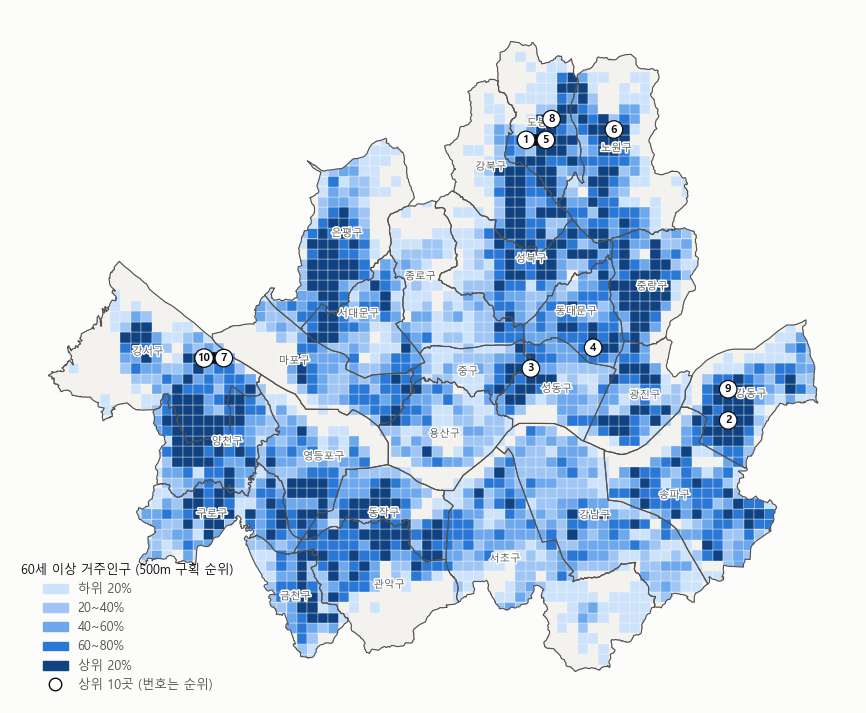

,자치구,60세이상_거주인구
순위,,
1,도봉구,"4,285"
2,강동구,"4,219"
3,성동구,"4,167"
4,동대문구,"4,131"
5,도봉구,"3,997"
6,노원구,"3,974"
7,강서구,"3,958"
8,도봉구,"3,933"
9,강동구,"3,910"


In [6]:
seoul = gu.geometry.union_all() if hasattr(gu.geometry, "union_all") else gu.geometry.unary_union

# 쉼터까지 직선거리. 격자 중심에서 잰다.
shelter = pd.read_csv(SHELTER_PATH, encoding="cp949").dropna(subset=["경도", "위도"])
shelter = gpd.GeoDataFrame(
    shelter, geometry=gpd.points_from_xy(shelter["경도"], shelter["위도"]), crs=4326).to_crs(5179)
dist, _ = cKDTree(np.column_stack([shelter.geometry.x, shelter.geometry.y])).query(
    np.column_stack([grid.geometry.x, grid.geometry.y]))
grid["dist_m"] = dist
grid["uncovered_old"] = grid["pop_old"].where(grid["dist_m"] > COVERAGE_DISTANCE_M, 0)

grid["bx"] = np.floor(grid.geometry.x / BLOCK_M).astype(int)
grid["by"] = np.floor(grid.geometry.y / BLOCK_M).astype(int)
block = grid.groupby(["bx", "by"]).agg(
    pop_old=("pop_old", "sum"),
    uncovered_old=("uncovered_old", "sum"),
    gu=("gu", lambda g: g.mode().iat[0]),
).reset_index()
block = gpd.GeoDataFrame(block, crs=5179, geometry=[
    box(x * BLOCK_M, y * BLOCK_M, (x + 1) * BLOCK_M, (y + 1) * BLOCK_M).intersection(seoul)
    for x, y in zip(block["bx"], block["by"])])
print(f"{BLOCK_M}m 구획:", f"{len(block):,}개")

block["q5"] = pd.qcut(block["pop_old"].rank(method="first"), 5, labels=False)
top_res = block.nlargest(TOP_N, "pop_old")

fig, ax = plt.subplots(figsize=(11, 9))
base_map(ax)
block.plot(ax=ax, color=[BLUE_RAMP[i] for i in block["q5"]], edgecolor=SURFACE, linewidth=0.25, zorder=2)
gu.boundary.plot(ax=ax, color=INK_SUB, linewidth=0.8, zorder=5)
gu_labels(ax, halo="white")
rank_badges(ax, top_res)
rank_legend(ax, BLUE_RAMP, ["하위 20%", "20~40%", "40~60%", "60~80%", "상위 20%"],
            f"{AGE_MIN}세 이상 거주인구 ({BLOCK_M}m 구획 순위)")
save(fig, "01_고령거주인구_지도.png")
plt.show()

display(top_res.assign(순위=range(1, TOP_N + 1))[["순위", "gu", "pop_old"]]
        .rename(columns={"gu": "자치구", "pop_old": f"{AGE_MIN}세이상_거주인구"})
        .set_index("순위").style.format("{:,.0f}", subset=[f"{AGE_MIN}세이상_거주인구"]))

## 4. 사각지대 지도

가장 가까운 쉼터가 기준거리 밖인 60세 이상 거주인구를 구획별로 더한다. `seoul_eda.ipynb` 3번 그림과 같은 형식으로, 상위 20% 구획만 칠한다.

기준거리 219m 밖에 사는 60세 이상 인구: 17.6% (직선거리 기준)


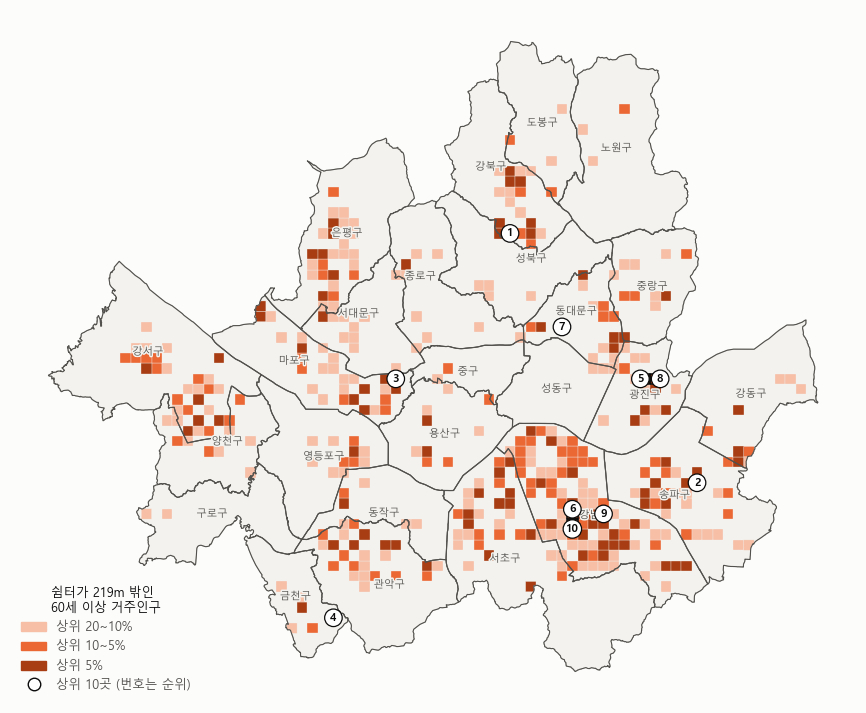

,자치구,미커버,60세이상_거주인구
순위,,,
1,강북구,"2,704","3,332"
2,송파구,"2,441","2,441"
3,마포구,"2,339","2,339"
4,금천구,"2,157","2,508"
5,광진구,"2,045","2,916"
6,강남구,"2,015","2,328"
7,동대문구,"2,006","2,950"
8,광진구,"1,995","2,491"
9,강남구,"1,897","2,294"


In [7]:
uncovered_share = grid["uncovered_old"].sum() / grid["pop_old"].sum() * 100
pct = block["uncovered_old"].rank(pct=True)
block["gap_class"] = np.select([pct > 0.95, pct > 0.90, pct > 0.80], [2, 1, 0], default=-1)
gap_blocks = block[block["gap_class"] >= 0]
top_gap = block.nlargest(TOP_N, "uncovered_old")

fig, ax = plt.subplots(figsize=(11, 9))
base_map(ax)
gap_blocks.plot(ax=ax, color=[ORANGE_RAMP[i] for i in gap_blocks["gap_class"]],
                edgecolor=LAND, linewidth=0.25, zorder=2)
gu.boundary.plot(ax=ax, color=INK_SUB, linewidth=0.8, zorder=5)
gu_labels(ax)
rank_badges(ax, top_gap)
rank_legend(ax, ORANGE_RAMP, ["상위 20~10%", "상위 10~5%", "상위 5%"],
            f"쉼터가 {COVERAGE_DISTANCE_M}m 밖인\n{AGE_MIN}세 이상 거주인구")
print(f"기준거리 {COVERAGE_DISTANCE_M}m 밖에 사는 {AGE_MIN}세 이상 인구: {uncovered_share:.1f}% (직선거리 기준)")
save(fig, "02_고령거주인구_사각지대_지도.png")
plt.show()

display(top_gap.assign(순위=range(1, TOP_N + 1))[["순위", "gu", "uncovered_old", "pop_old"]]
        .rename(columns={"gu": "자치구", "uncovered_old": "미커버", "pop_old": f"{AGE_MIN}세이상_거주인구"})
        .set_index("순위").style.format("{:,.0f}", subset=["미커버", f"{AGE_MIN}세이상_거주인구"]))

## 5. 자치구별 집계

지도에 쓴 값을 자치구로 더해 표로 남긴다.

In [8]:
gu_tab = grid.groupby("gu").agg(
    거주인구_고령=("pop_old", "sum"),
    미커버_고령=("uncovered_old", "sum"),
)
gu_tab["주민등록인구"] = dong_pop.groupby("시군구명")["계"].sum()
gu_tab["고령비율_pct"] = gu_tab["거주인구_고령"] / gu_tab["주민등록인구"] * 100
gu_tab["쉼터수"] = gpd.sjoin(shelter, gu, predicate="within").groupby("gu").size()
gu_tab["커버율_pct"] = (1 - gu_tab["미커버_고령"] / gu_tab["거주인구_고령"]) * 100
gu_tab["고령1만명당_쉼터"] = gu_tab["쉼터수"] / gu_tab["거주인구_고령"] * 10_000
gu_tab = gu_tab.sort_values("커버율_pct")

if SAVE:
    gu_tab.to_csv(OUT / "03_자치구별_고령거주인구_커버율.csv", encoding="utf-8-sig")

display(gu_tab.style.format({
    "거주인구_고령": "{:,.0f}", "미커버_고령": "{:,.0f}", "주민등록인구": "{:,.0f}",
    "고령비율_pct": "{:.1f}", "쉼터수": "{:,.0f}", "커버율_pct": "{:.1f}", "고령1만명당_쉼터": "{:.1f}",
}))

,거주인구_고령,미커버_고령,주민등록인구,고령비율_pct,쉼터수,커버율_pct,고령1만명당_쉼터
gu,,,,,,,
강남구,"130,026","78,724","551,907",23.6,98,39.5,7.5
서초구,"100,296","40,021","420,794",23.8,145,60.1,14.5
마포구,"85,380","29,498","355,806",24.0,90,65.5,10.5
종로구,"42,112","10,436","135,842",31.0,116,75.2,27.5
광진구,"87,641","21,602","330,589",26.5,100,75.4,11.4
동대문구,"99,100","22,341","353,511",28.0,107,77.5,10.8
용산구,"54,686","12,094","199,192",27.5,101,77.9,18.5
강북구,"99,436","21,643","277,307",35.9,97,78.2,9.8
송파구,"167,771","34,990","648,138",25.9,206,79.1,12.3


## 해석할 때 주의할 점

- 거주인구는 밤에 집에 있는 사람이다. 폭염 시간대(낮)에 그 자리에 있는 사람은 유동인구가 더 가깝다. 이 노트북은 유동인구 결과와 나란히 놓고 차이를 보는 용도다.
- 격자 안의 고령 인구는 추정값이다. 행정동 합계만 실제 통계이고, 동 안의 분포는 총인구 분포를 따른다고 가정했다.
- `Seoul_Test_Population.csv`의 출처와 기준 시점을 확인해야 한다. 2번 표에 나온 동은 격자 시점 이후 인구가 크게 바뀐 곳이다. 균등배분한 동은 동 안의 위치 정보가 없다.
- 거리는 전부 직선거리다. 보고서에 넣을 커버율은 `Seoul.ipynb`의 보행 네트워크 거리로 다시 계산한다.